# Simulated Annealing Schedules

Michael Hahsler

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

## Cooling Schedules

### Exponential Schedule

See [1].

In [ ]:
def temperature_exponential(time, initial_temperature, alpha):
    return initial_temperature * alpha**time

### Linear Schedule

See [1].

In [ ]:
def temperature_linear(time, initial_temperature, eta):
    return initial_temperature - eta * time

### Fast Simulated Annealing

See [3].

In [ ]:
def temperature_fast(time, initial_temperature):
    return initial_temperature / (1 + time)

### Logarithmic (Classic) Cooling

If $T_0$ is greater than or equal to the largest energy barrier in the problem, this schedule is guaranteed to find the global optimum in the limit of infinite time [2]. The schedule is defined for $t > 0$.

In [ ]:
def temperature_logarithmic(time, initial_temperature):
    return initial_temperature / np.log1p(time)

## Comparison

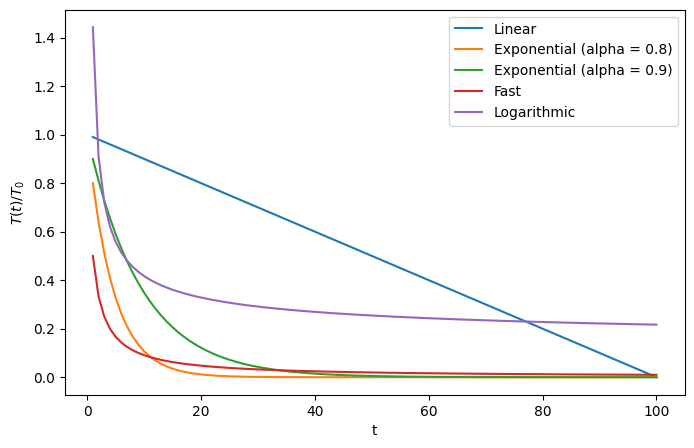

In [ ]:
time = np.arange(1, 101)
initial_temperature = 1

schedules = {
    "Linear": temperature_linear(time, initial_temperature, eta=0.01),
    "Exponential (alpha = 0.8)": temperature_exponential(
        time, initial_temperature, alpha=0.8
    ),
    "Exponential (alpha = 0.9)": temperature_exponential(
        time, initial_temperature, alpha=0.9
    ),
    "Fast": temperature_fast(time, initial_temperature),
    "Logarithmic": temperature_logarithmic(time, initial_temperature),
}

plt.figure(figsize=(8, 5))
for name, temperature in schedules.items():
    plt.plot(time, temperature / initial_temperature, label=name)

plt.xlabel("t")
plt.ylabel(r"$T(t) / T_0$")
plt.legend()
plt.show()

**Nhận xét đồ thị trên** (cùng $T_0 = 1$, t = 1..100): `Fast` và `Logarithmic` rơi rất nhanh ở đầu rồi bò chậm (đuôi dài). `Exponential` giảm đều theo tỉ lệ, alpha = 0.8 nguội nhanh hơn alpha = 0.9. `Linear` (eta = 0.01) giảm đều đến đúng 0 ở t = 100. Riêng `Logarithmic` ở t = 1 cho $T_0/\ln 2 \approx 1.44\,T_0$ nên lớn hơn $T_0$, vì công thức chỉ định nghĩa cho t > 0 và chia cho $\ln(1+t)$ (với t < e - 1 thì mẫu số < 1).

## Thay đổi alpha, eta và T0: lịch nào chấp nhận bước xấu lâu hơn?

Khi gặp nước đi xấu hơn $\Delta > 0$, SA nhận nó với xác suất $p = e^{-\Delta/T}$. Lấy $\Delta = 1$ (ví dụ thêm 1 xung đột trong n-Queens). Để biết lịch nào "chấp nhận bước xấu lâu hơn" mình vẽ **xác suất chấp nhận $p(t)$** theo thời gian khi đổi từng tham số, và đếm **số bước t mà $p \ge 5\%$**, tức $T(t) \ge 1/\ln 20 \approx 0.334$. Số bước này càng lớn thì thuật toán khám phá (chấp nhận bước xấu) càng lâu.

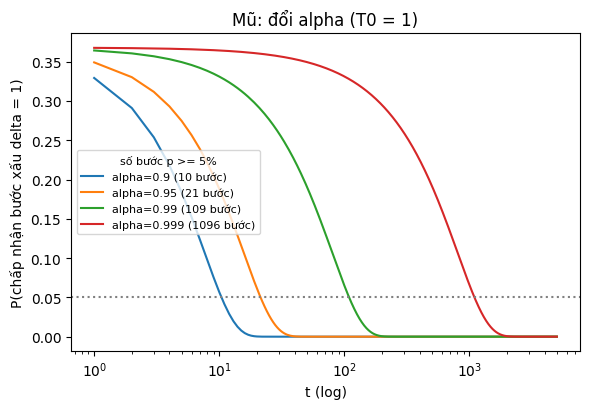

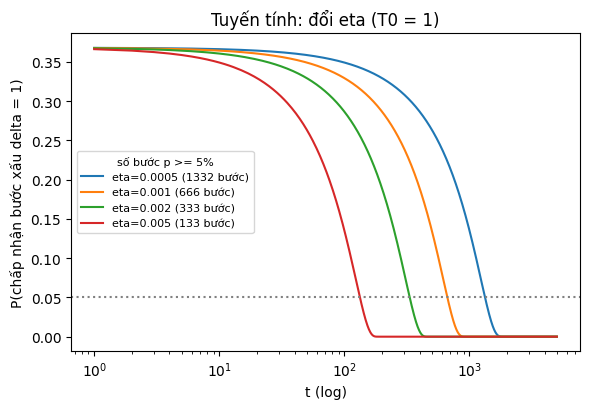

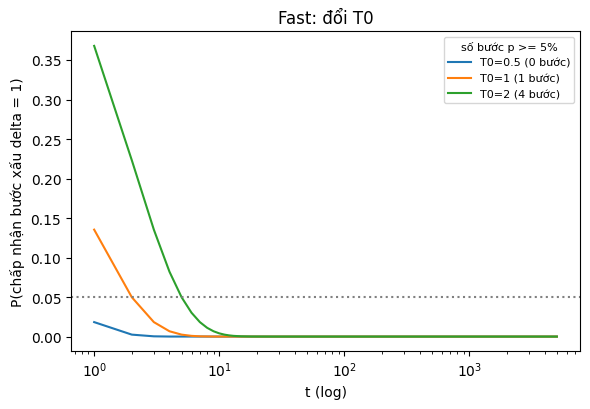

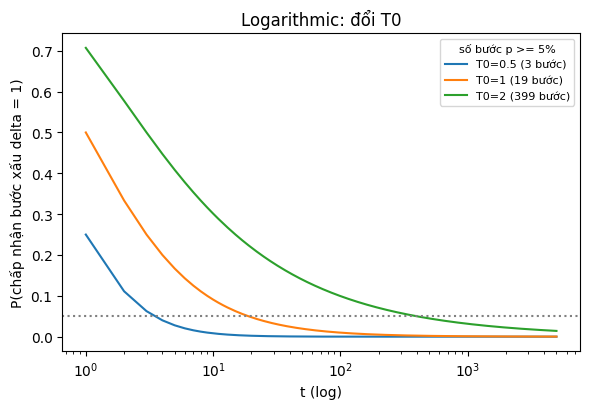

In [ ]:
p_min = 0.05
T_thr = 1 / np.log(1 / p_min)          # T tối thiểu để P(chấp nhận delta=1) >= 5%
H = 10**6                              # khoảng thời gian khảo sát để đếm số bước
tt_all = np.arange(1, H + 1)

def steps_exploring(T):                 # số bước có T >= ngưỡng
    return int(np.sum(T >= T_thr))

def accept_prob(T):
    with np.errstate(over="ignore", divide="ignore"):
        return np.exp(-1 / np.maximum(T, 1e-9))

tp = np.arange(1, 5001)                 # khoảng thời gian để vẽ

def finish_plot(title):
    """Phần trang trí chung cho mỗi hình: vạch p = 5%, trục, chú thích."""
    plt.axhline(p_min, color="gray", ls=":")
    plt.xscale("log")
    plt.xlabel("t (log)")
    plt.ylabel("P(chấp nhận bước xấu delta = 1)")
    plt.title(title)
    plt.legend(fontsize=8, title="số bước p >= 5%", title_fontsize=8)
    plt.tight_layout()
    plt.show()

# (a) Lịch mũ: đổi alpha, T0 = 1
plt.figure(figsize=(6, 4.2))
for a in (0.9, 0.95, 0.99, 0.999):
    plt.plot(tp, accept_prob(temperature_exponential(tp, 1, a)),
             label=f"alpha={a} ({steps_exploring(temperature_exponential(tt_all, 1, a))} bước)")
finish_plot("Mũ: đổi alpha (T0 = 1)")

# (b) Lịch tuyến tính: đổi eta, T0 = 1
plt.figure(figsize=(6, 4.2))
for eta in (0.0005, 0.001, 0.002, 0.005):
    plt.plot(tp, accept_prob(temperature_linear(tp, 1, eta)),
             label=f"eta={eta} ({steps_exploring(temperature_linear(tt_all, 1, eta))} bước)")
finish_plot("Tuyến tính: đổi eta (T0 = 1)")

# (c) Lịch fast: đổi T0
plt.figure(figsize=(6, 4.2))
for T0 in (0.5, 1, 2):
    plt.plot(tp, accept_prob(temperature_fast(tp, T0)),
             label=f"T0={T0} ({steps_exploring(temperature_fast(tt_all, T0))} bước)")
finish_plot("Fast: đổi T0")

# (d) Lịch logarithmic: đổi T0
plt.figure(figsize=(6, 4.2))
for T0 in (0.5, 1, 2):
    plt.plot(tp, accept_prob(temperature_logarithmic(tp, T0)),
             label=f"T0={T0} ({steps_exploring(temperature_logarithmic(tt_all, T0))} bước)")
finish_plot("Logarithmic: đổi T0")

In [ ]:
# Bảng số bước còn chấp nhận bước xấu (p >= 5%), các lịch ở các T0 khác nhau
import pandas as pd
rows = []
for T0 in (1, 2, 5):
    scheds = {
        "Linear (eta=T0/1000)":      temperature_linear(tt_all, T0, T0 / 1000),
        "Exponential (alpha=0.99)":  temperature_exponential(tt_all, T0, 0.99),
        "Exponential (alpha=0.999)": temperature_exponential(tt_all, T0, 0.999),
        "Fast":                      temperature_fast(tt_all, T0),
        "Logarithmic":               temperature_logarithmic(tt_all, T0),
    }
    for name, T in scheds.items():
        rows.append({"T0": T0, "schedule": name, "số bước p>=5%": steps_exploring(T)})
tab = pd.DataFrame(rows).pivot(index="schedule", columns="T0", values="số bước p>=5%").sort_values(1, ascending=False)
print(f"Ngưỡng T = {T_thr:.3f}; khảo sát t = 1..{H:,} (giá trị = {H:,} nghĩa là vẫn còn chấp nhận đến hết khoảng khảo sát)")
tab

Ngưỡng T = 0.334; khảo sát t = 1..1,000,000 (giá trị = 1,000,000 nghĩa là vẫn còn chấp nhận đến hết khoảng khảo sát)


T0,1,2,5
schedule,,,
Exponential (alpha=0.999),1096,1789,2705
Linear (eta=T0/1000),666,833,933
Exponential (alpha=0.99),109,178,269
Logarithmic,19,399,1000000
Fast,1,4,13


## Nhận xét

**Lịch nào làm SA chấp nhận bước xấu lâu hơn?** (bước xấu $\Delta=1$, đếm số bước có xác suất chấp nhận $\ge 5\%$)

* **Đổi alpha (lịch mũ, $T_0 = 1$):** $\alpha$ = 0.9, 0.95, 0.99, 0.999 cho 10, 21, 109, 1096 bước. $\alpha$ càng gần 1 thì nguội càng chậm, chấp nhận bước xấu càng lâu (tăng khoảng 10 lần mỗi khi $1-\alpha$ giảm 10 lần).
* **Đổi eta (lịch tuyến tính, $T_0 = 1$):** $\eta$ = 0.005, 0.002, 0.001, 0.0005 cho 133, 333, 666, 1332 bước. $\eta$ càng nhỏ thì T giảm càng chậm nên chấp nhận bước xấu càng lâu (tỉ lệ nghịch với $\eta$).
* **Đổi $T_0$:** $T_0$ lớn hơn thì mọi lịch đều "nóng" lâu hơn, nhưng mức độ khác nhau. Fast: 0 / 1 / 4 bước với $T_0$ = 0.5 / 1 / 2. Logarithmic: 3 / 19 / 399 bước, tăng rất mạnh (cỡ $e^{3T_0}$, với $T_0 = 5$ vượt mốc 1 triệu bước). Mũ ($\alpha$ = 0.99) tăng chậm: 109 / 178 / 269 bước với $T_0$ = 1 / 2 / 5.
* **So sánh các lịch ở cùng $T_0 = 1$:** mũ $\alpha$ = 0.999 (~1100) > tuyến tính $\eta$ = 0.001 (~670) > mũ $\alpha$ = 0.99 (~110) > logarithmic (19) > fast (1). Kết luận: **fast nguội nhanh nhất** (gần như thành hill climbing ngay sau vài bước), còn lịch nào chấp nhận bước xấu lâu nhất thì **phụ thuộc tham số**: mũ với $\alpha$ sát 1 và tuyến tính với $\eta$ nhỏ thì lâu, logarithmic chỉ lâu khi $T_0$ đủ lớn.
* Lịch tuyến tính giữ nhiệt cao rồi rơi khá đột ngột về 0 (đồ thị xác suất của nó có hình "bậc thang"), còn mũ giảm trơn hơn.

**Liên hệ với thực nghiệm n-Queens (notebook `n_queens.ipynb`, Task 5):** lịch cho nhiều bước nóng hơn (mũ $\alpha$ = 0.999, tuyến tính) có tỉ lệ ra lời giải 99-100%, trong khi lịch nguội nhanh (fast, mũ $\alpha$ = 0.99) chỉ 70-75%, đổi lại chạy nhanh hơn 2-4 lần. Trong thí nghiệm mình chọn mũ với $\alpha$ = 0.999 vì dễ chỉnh và cân bằng giữa chất lượng và thời gian.

## Literature

1. Kirkpatrick, S., Gelatt, C. D. Jr., and Vecchi, M. P. (1983). Optimization by simulated annealing. *Science*, 220, 671–680.
2. Hajek, B. (1988). Cooling schedules for optimal annealing. *Mathematics of Operations Research*, 13, 311–329.
3. Szu, H., and Hartley, R. (1987). Fast simulated annealing. *Physics Letters A*, 122(3–4), 157–162. [doi:10.1016/0375-9601(87)90796-1](https://doi.org/10.1016/0375-9601(87)90796-1)